# Semana 4 · Validar un modelo sin hacerse trampa

**Prácticas y Herramientas de Big Data · UIDE**

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/carlosandresat/uide-big-data-online/blob/main/semana-04/ejemplos/validacion-vinos.ipynb)

**Cómo usar este notebook en Colab**
1. Ábrelo con el botón de arriba.
2. **Archivo → Guardar una copia en Drive.** Así puedes editarlo y tus cambios quedan en tu cuenta.
3. Ejecuta cada celda con **Shift + Enter**, en orden. La primera tarda unos segundos porque Colab enciende la máquina.

✋ **Tu turno**: cambia algo y mira qué pasa. 🔎 **Interpreta**: preguntas para pensar antes de seguir.

Seguimos con los vinos tintos de la semana 3 (*Wine Quality*, Cortez y otros, 2009, repositorio UCI, licencia CC BY 4.0): ¿es bueno (puntaje 6 o más) o regular?

## 1. Los datos (lo mismo que la semana 3, en una sola celda)

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import MinMaxScaler
from sklearn.pipeline import make_pipeline
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import train_test_split, cross_val_score, KFold, StratifiedKFold

URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
COPIA = "https://raw.githubusercontent.com/carlosandresat/uide-big-data-online/main/semana-03/ejemplos/datos/winequality-red.csv"
try:
    vinos = pd.read_csv(URL, sep=";")
except Exception:                      # si el repositorio UCI no responde, usamos la copia del curso
    vinos = pd.read_csv(COPIA, sep=";")

vinos = vinos.rename(columns={"volatile acidity": "acidez_volatil", "sulphates": "sulfatos", "quality": "puntaje"})
vinos = vinos.drop_duplicates()                                   # semana 2: fuera los 240 repetidos
vinos["calidad"] = np.where(vinos["puntaje"] >= 6, "bueno", "regular")

PREDICTORAS = ["alcohol", "sulfatos", "acidez_volatil"]
X, y = vinos[PREDICTORAS], vinos["calidad"]
print(X.shape, y.value_counts().to_dict())

(1359, 3) {'bueno': 719, 'regular': 640}


## 2. La curva de sobreajuste

Separamos el 25 % de los vinos para **prueba** antes de hacer cualquier otra cosa. Después entrenamos árboles cada vez más profundos y medimos su exactitud en los dos conjuntos.

In [2]:
X_ent, X_pru, y_ent, y_pru = train_test_split(X, y, test_size=0.25, random_state=42)

filas = []
for profundidad in [1, 2, 3, 4, 5, 6, 8, 10, 12, None]:
    arbol = DecisionTreeClassifier(max_depth=profundidad, random_state=0).fit(X_ent, y_ent)
    filas.append({"profundidad": "sin límite" if profundidad is None else profundidad,
                  "entrenamiento": arbol.score(X_ent, y_ent),
                  "prueba": arbol.score(X_pru, y_pru)})
curva = pd.DataFrame(filas)
curva["diferencia"] = curva["entrenamiento"] - curva["prueba"]
curva.round(3)

,profundidad,entrenamiento,prueba,diferencia
0,1,0.713,0.694,0.019
1,2,0.713,0.694,0.019
2,3,0.739,0.732,0.007
3,4,0.752,0.718,0.034
4,5,0.775,0.735,0.040
5,6,0.792,0.721,0.071
6,8,0.850,0.726,0.123
7,10,0.893,0.706,0.187
8,12,0.922,0.709,0.214
9,sin límite,0.995,0.688,0.307


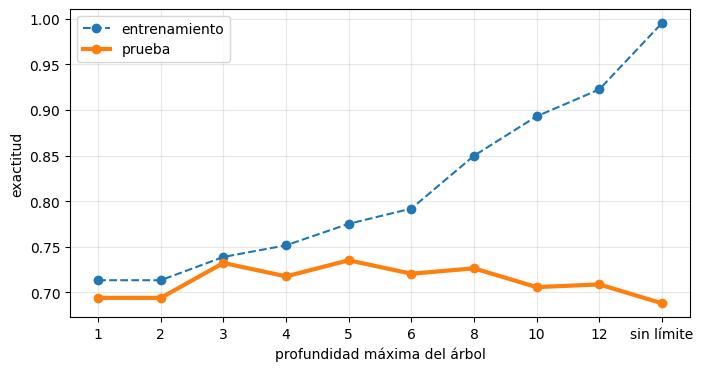

In [3]:
plt.figure(figsize=(8, 4))
plt.plot(curva["profundidad"].astype(str), curva["entrenamiento"], "o--", label="entrenamiento")
plt.plot(curva["profundidad"].astype(str), curva["prueba"], "o-", linewidth=3, label="prueba")
plt.xlabel("profundidad máxima del árbol")
plt.ylabel("exactitud")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

🔎 **Interpreta.**
- **Izquierda (profundidad 1 y 2):** las dos curvas están bajas y juntas. El modelo es demasiado simple: **subajuste** (mucho sesgo).
- **Derecha (sin límite):** casi 100 % en entrenamiento y la peor prueba. Memorizó el ruido: **sobreajuste** (mucha varianza). La señal es la **diferencia** entre las dos curvas.
- **En medio (3 a 5):** el punto dulce. Pero fíjate: 0,732, 0,718, 0,735… la prueba sube y baja por poco. ¿Podemos confiar en una sola división?

## 3. Una sola división engaña: validación cruzada K-Fold

### 3.1 La misma prueba, con otra semilla
`random_state` decide qué vinos caen en prueba. Cambiémoslo 10 veces con el mismo árbol de profundidad 3.

In [4]:
resultados = []
for semilla in range(10):
    a, b, c, d = train_test_split(X, y, test_size=0.25, random_state=semilla)
    resultados.append(DecisionTreeClassifier(max_depth=3, random_state=0).fit(a, c).score(b, d))
print(np.round(resultados, 3))
print(f"De {min(resultados):.3f} a {max(resultados):.3f}, según qué vinos tocaron en prueba")

[0.679 0.665 0.706 0.721 0.729 0.715 0.729 0.697 0.7   0.741]
De 0.665 a 0.741, según qué vinos tocaron en prueba


### 3.2 K-Fold
Dividimos los vinos en **5 pliegues**. Entrenamos 5 veces: cada vez un pliegue es la prueba y los otros 4 entrenan. Cada vino prueba exactamente una vez. Reportamos el **promedio** y la **dispersión**.

In [5]:
cinco_pliegues = KFold(n_splits=5, shuffle=True, random_state=0)
puntajes = cross_val_score(DecisionTreeClassifier(max_depth=3, random_state=0), X, y, cv=cinco_pliegues)
print("Exactitud por pliegue:", np.round(puntajes, 3))
print(f"Media = {puntajes.mean():.3f}   desviación = {puntajes.std():.3f}")

Exactitud por pliegue: [0.684 0.71  0.71  0.691 0.708]
Media = 0.701   desviación = 0.011


### 3.3 Elegir la profundidad con K-Fold
Ahora sí comparamos profundidades con una medida estable: la media de 5 pliegues.

In [6]:
for profundidad in [1, 2, 3, 4, 5, 6, 8, None]:
    p = cross_val_score(DecisionTreeClassifier(max_depth=profundidad, random_state=0), X, y, cv=cinco_pliegues)
    print(f"profundidad {str(profundidad):>4}:  media = {p.mean():.3f}   desviación = {p.std():.3f}")

profundidad    1:  media = 0.695   desviación = 0.026


profundidad    2:  media = 0.696   desviación = 0.016
profundidad    3:  media = 0.701   desviación = 0.011


profundidad    4:  media = 0.708   desviación = 0.013


profundidad    5:  media = 0.713   desviación = 0.021


profundidad    6:  media = 0.708   desviación = 0.017
profundidad    8:  media = 0.689   desviación = 0.020


profundidad None:  media = 0.655   desviación = 0.016

🔎 **Interpreta.** K-Fold no **previene** el sobreajuste: lo **detecta** con una estimación más fiable, porque usa todas las filas para probar. Con esa estimación elegimos la profundidad.

✋ **Tu turno (4 minutos).** Esta celda valida el KNN de la semana 3 (15 vecinos, con el escalado dentro de un pipeline). Cambia `n_splits` por 2, 10 y 20. Anota la media, la desviación y el tiempo. ¿Qué pasa con la media cuando K es muy bajo? ¿Y con el tiempo cuando K sube?

In [7]:
pliegues = KFold(n_splits=5, shuffle=True, random_state=0)      # cambia el 5
inicio = time.time()
knn15 = make_pipeline(MinMaxScaler(), KNeighborsClassifier(n_neighbors=15))
p = cross_val_score(knn15, X, y, cv=pliegues)
print(f"K = {pliegues.n_splits}: entrena con ~{len(X) - len(X) // pliegues.n_splits} vinos cada vez · "
      f"media = {p.mean():.3f} · desviación = {p.std():.3f} · {time.time() - inicio:.3f} s")

K = 5: entrena con ~1088 vinos cada vez · media = 0.747 · desviación = 0.018 · 0.118 s


## 4. La IA valida un modelo… y se hace trampa sin querer

Le pedimos a la IA: *«Tengo 100 pacientes con 5000 medidas genéticas cada uno y si respondieron o no a un tratamiento. Elige las 20 mejores variables y evalúa un modelo con validación cruzada de 5 pliegues»*.

Truco: los datos que le damos son **ruido puro**, generados al azar. Ningún modelo honesto puede acertar mucho más del 50 %.

In [8]:
rng = np.random.default_rng(7)
X_genes = rng.normal(size=(100, 5000))                 # 5000 columnas de ruido
y_genes = rng.permutation([0] * 50 + [1] * 50)         # respuesta al tratamiento, sorteada
pliegues_genes = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

# --- Lo que escribió la IA ---
X_sel = SelectKBest(f_classif, k=20).fit_transform(X_genes, y_genes)   # elige mirando las 100 filas
con_fuga = cross_val_score(LogisticRegression(max_iter=1000), X_sel, y_genes, cv=pliegues_genes)
print(f"Versión de la IA: {con_fuga.mean():.2f}")

Versión de la IA: 0.93


🔎 **Interpreta.** ¿Le crees a ese resultado? `SelectKBest` eligió las 20 columnas que mejor separan las clases **usando las 100 filas**, también las que después hacen de prueba. Con 5000 columnas de ruido, alguna coincide por azar con las etiquetas. La prueba ya estaba «vista»: es una **fuga de datos**. Y es un ejemplo de por qué muchas **variables irrelevantes** favorecen el sobreajuste.

La versión honesta mete la selección dentro de un **pipeline**: se repite en cada pliegue, solo con las filas de entrenamiento.

In [9]:
honesto = make_pipeline(SelectKBest(f_classif, k=20), LogisticRegression(max_iter=1000))
sin_fuga = cross_val_score(honesto, X_genes, y_genes, cv=pliegues_genes)
print(f"Versión honesta: {sin_fuga.mean():.2f}   pliegues: {np.round(sin_fuga, 2)}")

Versión honesta: 0.54   pliegues: [0.4  0.55 0.6  0.6  0.55]


**Regla:** todo lo que aprende de los datos (`fit`) va **después** de separar y solo con entrenamiento: elegir variables, imputar faltantes y escalar con `MinMaxScaler`.

## 5. Elegir K de KNN sin hacer trampa (así se hace en el Aprendizaje Autónomo 2)

La semana 3 elegimos K mirando la prueba, solo para ilustrar. Lo correcto:
1. Separar la prueba y **no tocarla**.
2. Elegir K con K-Fold **dentro del entrenamiento**, con el escalado dentro de un pipeline.
3. Evaluar **una sola vez** en prueba el K elegido.

In [10]:
for k in [1, 5, 15, 31, 51, 101]:
    knn = make_pipeline(MinMaxScaler(), KNeighborsClassifier(n_neighbors=k))
    p = cross_val_score(knn, X_ent, y_ent, cv=cinco_pliegues)
    print(f"K = {k:>3}: media en validación = {p.mean():.3f}")

K =   1: media en validación = 0.665
K =   5: media en validación = 0.694


K =  15: media en validación = 0.726


K =  31: media en validación = 0.729


K =  51: media en validación = 0.735


K = 101: media en validación = 0.728


In [11]:
mejor = make_pipeline(MinMaxScaler(), KNeighborsClassifier(n_neighbors=51)).fit(X_ent, y_ent)
print(f"K = 51 en prueba (una sola vez): {mejor.score(X_pru, y_pru):.3f}")

K = 51 en prueba (una sola vez): 0.753


🔎 **Interpreta.** El pipeline ajusta el `MinMaxScaler` dentro de cada pliegue, solo con las filas que entrenan. La prueba se usa una sola vez, al final: por eso su exactitud es una estimación honesta de cómo le irá con vinos nuevos.

## 6. ✋ Ejercicio individual (si ves la grabación, o para practicar)

1. En el **Tu turno** de la sección 3, prueba K = 2, 5, 10 y 20. ¿Con qué K la media es más baja, y por qué? ¿Cómo crece el tiempo?
2. En la sección 4, cambia 5000 columnas por 50 en las dos celdas. ¿La fuga infla más o menos el resultado? ¿Por qué?
3. **Para el Aprendizaje Autónomo 2:** con **tu dataset**, dibuja la curva de sobreajuste de un árbol (sección 2) y elige el K de tu KNN como en la sección 5. Explica en un párrafo qué K elegiste y por qué.

## Anexo · La animación de K-Fold de la presentación (flores iris)

In [12]:
from sklearn.datasets import load_iris
iris = load_iris()
p = cross_val_score(make_pipeline(MinMaxScaler(), KNeighborsClassifier(n_neighbors=5)), iris.data, iris.target,
                    cv=KFold(n_splits=5, shuffle=True, random_state=0))
print("Pliegues:", np.round(p, 3), f"· media = {p.mean():.3f} · desviación = {p.std():.3f}")

Pliegues: [1.    0.867 1.    1.    0.933] · media = 0.960 · desviación = 0.053
